身份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 1. 填写学号 =====
STUDENT_ID = "2024080204"  # 修改为你的学号

# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# ===== 3. 机器指纹（绑定当前电脑） =====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

print(f"NumPy 版本: {np.__version__}")
print(f"pandas 版本: {pd.__version__}")

[Conda 环境] exp01
[学号] 2024080204
[机器指纹] d39e8ab5aaea03ce
[RUN_ID] 2024080204-d39e8ab5aaea03ce
NumPy 版本: 2.2.6
pandas 版本: 2.3.3


实验1：NumPy数组、数据类型与索引

In [2]:
# 1. 创建不同类型的 ndarray 并查看属性
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

print(f"整数数组: dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print(f"浮点数组: dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print(f"布尔数组: dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")
# Markdown解释：NumPy要求数组内所有元素类型相同（同质），而Python列表可以混合存放不同类型。

# 2. 形状变换
arr_1d = np.arange(12)
arr_3x4 = arr_1d.reshape(3, 4)
arr_2x3x2 = arr_1d.reshape(2, 3, 2)
print(f"\n(3,4) 数组:\n{arr_3x4}")
print(f"\n(2,3,2) 数组:\n{arr_2x3x2}")
# Markdown解释：改变形状时，元素总数必须保持不变。

# 3. 索引
print(f"\n第2行: {arr_3x4[1]}")
print(f"第1至第3列: \n{arr_3x4[:, 0:3]}")
mask = arr_3x4 > 6
print(f"大于6的元素: {arr_3x4[mask]}, 形状: {arr_3x4[mask].shape}")

# 4. 条件筛选
arr_10 = np.arange(10)
print(f"\n小于2或大于7: {arr_10[(arr_10 < 2) | (arr_10 > 7)]}")
print(f"大于3且小于7: {arr_10[(arr_10 > 3) & (arr_10 < 7)]}")

# 5. 逐元素乘法 vs 矩阵乘法
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])
print(f"\n逐元素乘法 (a*b):\n{a * b}")
print(f"矩阵乘法 (a@b):\n{a @ b}")
# Markdown解释：* 是逐元素对应相乘；@ 是线性代数中的矩阵乘法（行乘列相加）。

整数数组: dtype=int64, shape=(3,), ndim=1
浮点数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1

(3,4) 数组:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2,3,2) 数组:
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

第2行: [4 5 6 7]
第1至第3列: 
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
大于6的元素: [ 7  8  9 10 11], 形状: (5,)

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]

逐元素乘法 (a*b):
[[ 5 12]
 [21 32]]
矩阵乘法 (a@b):
[[19 22]
 [43 50]]


Markdown 1：NumPy数组与Python列表的差别
NumPy 数组要求所有元素的数据类型必须相同（同质），这使得它在内存中连续存储，计算效率极高；而 Python 列表可以混合存放不同类型的数据，结构更加灵活但计算较慢。

Markdown 2：改变形状的条件
改变数组形状（reshape）时，必须保证改变前后的元素总数完全相等。例如，np.arange(12) 有12个元素，可以重塑为 (3, 4) 或 (2, 3, 2)，因为它们的乘积都是12。

Markdown 3：逐元素乘法与矩阵乘法的区别
* 和 np.multiply() 表示逐元素乘法，即两个形状相同的数组对应位置上的元素直接相乘；@ 和 np.matmul() 表示矩阵乘法，要求前一个矩阵的列数等于后一个矩阵的行数，遵循“行乘列相加”的线性代数规则。

实验2：随机抽样、统计与缺失值

In [3]:
# 1. 模拟成绩生成与统计
np.random.seed(42)  # 固定随机种子
scores = np.random.normal(loc=70, scale=10, size=1000)
scores_clipped = np.clip(scores, 0, 100)
print(f"样本数: {len(scores_clipped)}, 最小值: {scores_clipped.min():.2f}, 最大值: {scores_clipped.max():.2f}")
print(f"均值: {scores_clipped.mean():.2f}, 标准差: {scores_clipped.std():.2f}, 极差: {scores_clipped.max() - scores_clipped.min():.2f}")

# 2. 抽样
arr_1_to_10 = np.arange(1, 11)
# 均匀抽样
uniform_sample = np.random.choice(arr_1_to_10, size=5, replace=False)
# 加权抽样 (例如权重与数值大小成正比)
weights = arr_1_to_10 / arr_1_to_10.sum()
weighted_sample = np.random.choice(arr_1_to_10, size=5, replace=False, p=weights)
print(f"\n均匀抽样: {uniform_sample}")
print(f"加权抽样: {weighted_sample}")

# 3. permutation vs shuffle
arr_demo = np.arange(5)
arr_permuted = np.random.permutation(arr_demo) # 保留原数组
print(f"\n原数组: {arr_demo}, permutation后副本: {arr_permuted}")

arr_demo2 = np.arange(5)
np.random.shuffle(arr_demo2) # 原地打乱
print(f"shuffle后原数组: {arr_demo2}")

# 4. 缺失值处理
scores_nan = scores_clipped.copy()
scores_nan[[9, 19, 29]] = np.nan  # 第10, 20, 30个变为NaN
print(f"\n普通均值(含NaN): {np.mean(scores_nan)}")
print(f"忽略NaN的均值: {np.nanmean(scores_nan):.2f}")
print(f"缺失值个数: {np.isnan(scores_nan).sum()}")
# Markdown解释：NaN参与普通计算会污染结果，使其变成NaN，需使用nanmean等专用函数。

# 5. 整理为pandas表格，供实验4使用
df_scores = pd.DataFrame({
    'Index': np.arange(1, 1001),
    'Score': scores_nan
})
print("已创建含缺失值的DataFrame `df_scores`，供实验4使用。")

样本数: 1000, 最小值: 37.59, 最大值: 100.00
均值: 70.18, 标准差: 9.76, 极差: 62.41

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]

原数组: [0 1 2 3 4], permutation后副本: [4 0 2 1 3]
shuffle后原数组: [0 4 1 3 2]

普通均值(含NaN): nan
忽略NaN的均值: 70.20
缺失值个数: 3
已创建含缺失值的DataFrame `df_scores`，供实验4使用。


Markdown 4：NaN 对统计函数的影响
np.nan（缺失值）具有“传染性”。在普通的统计函数（如 np.mean、np.sum）中，只要数组中包含任何一个 NaN，计算结果就会变成 NaN。因此，处理缺失值时必须使用专门的忽略 NaN 的函数（如 np.nanmean），或者先清除缺失值再进行计算。

实验3：SciPy 数值计算与 Matplotlib 可视化

线性方程组解: x=2.0, y=3.0
验证 Ax=b: True

正根: 1.4142, 成功: True, 函数值: -8.88e-16
负根: -1.4142, 成功: True, 函数值: -8.88e-16

极小值点: -0.50, 极小值: 1.75

t统计量: -8.5515, p值: 3.2930e-15


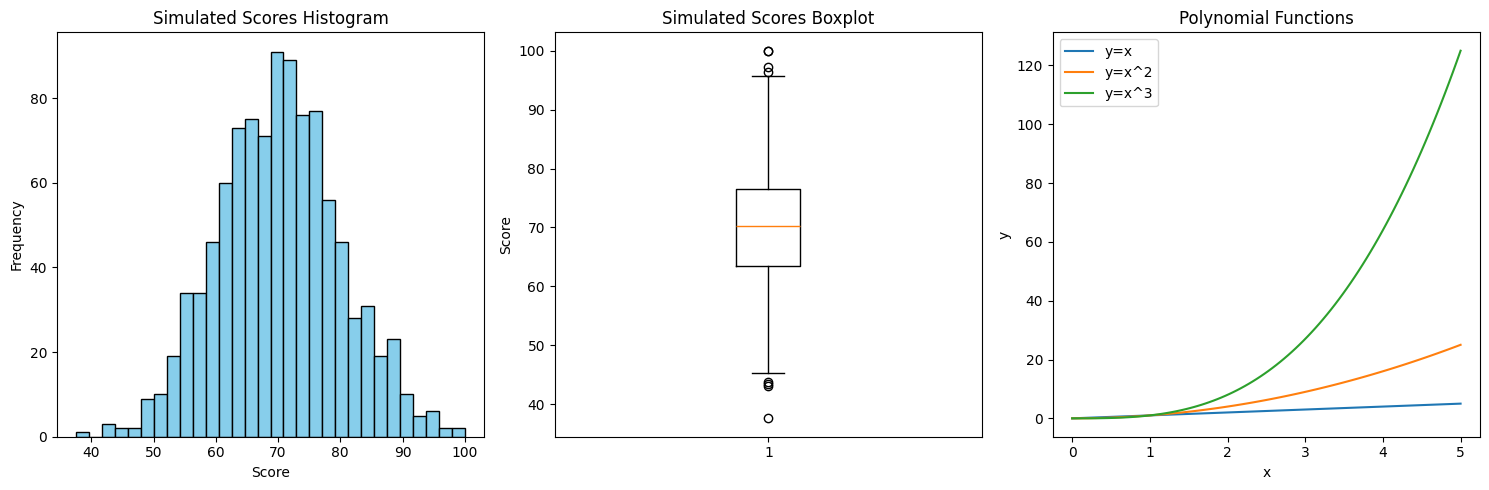

In [4]:
import scipy.linalg as la
import scipy.optimize as opt
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. 解线性方程组
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = la.solve(A, b)
print(f"线性方程组解: x={sol[0]}, y={sol[1]}")
print(f"验证 Ax=b: {np.allclose(np.dot(A, sol), b)}")

# 2. 求根
def f_root(x):
    return x**2 - 2

res_pos = opt.root(f_root, x0=1)  # 正根
res_neg = opt.root(f_root, x0=-1) # 负根
print(f"\n正根: {res_pos.x[0]:.4f}, 成功: {res_pos.success}, 函数值: {res_pos.fun[0]:.2e}")
print(f"负根: {res_neg.x[0]:.4f}, 成功: {res_neg.success}, 函数值: {res_neg.fun[0]:.2e}")

# 3. 求极小值
def f_min(x):
    return x**2 + x + 2

res_min = opt.minimize(f_min, x0=0)
print(f"\n极小值点: {res_min.x[0]:.2f}, 极小值: {res_min.fun:.2f}")
# Markdown解释：解析解极值点为 x=-b/(2a) = -0.5，最小值为 (-0.5)^2 - 0.5 + 2 = 1.75。计算结果一致。

# 4. t 检验
np.random.seed(42)
group1 = np.random.normal(loc=0, scale=1, size=100)
group2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = stats.ttest_ind(group1, group2)
print(f"\nt统计量: {t_stat:.4f}, p值: {p_val:.4e}")
# Markdown解释：p < 0.05，拒绝原假设，说明两组均值有显著差异。

# 5. 可视化
plt.figure(figsize=(15, 5))

# 直方图
plt.subplot(1, 3, 1)
plt.hist(scores_clipped, bins=30, color='skyblue', edgecolor='black')
plt.title("Simulated Scores Histogram")
plt.xlabel("Score")
plt.ylabel("Frequency")

# 箱线图
plt.subplot(1, 3, 2)
plt.boxplot(scores_clipped)
plt.title("Simulated Scores Boxplot")
plt.ylabel("Score")

# 折线图
plt.subplot(1, 3, 3)
x = np.linspace(0, 5, 100)
plt.plot(x, x, label="y=x")
plt.plot(x, x**2, label="y=x^2")
plt.plot(x, x**3, label="y=x^3")
plt.title("Polynomial Functions")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.tight_layout()
plt.show()

Markdown 5：优化结果与解析结果的对比
解析解求导可得 
f′(x)=2x+1=0f ′ (x)=2x+1=0，所以极值点为 x=−0.5。代入原函数得到极小值为 (−0.5)2−0.5+2=1.75。scipy.optimize.minimize() 的运行结果与解析结果完全一致。

Markdown 6：独立样本 t 检验结论
计算得出 p 值远小于 0.05 的显著性水平。因此，我们拒绝原假设，认为这两组来自不同正态分布的样本均值之间存在显著差异。

实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [5]:
# 1. 创建 DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)
print(f"行索引: {df.index.tolist()}")
print(f"列名: {df.columns.tolist()}")
print(f"前3行:\n{df.head(3)}")
print(f"基本统计:\n{df.describe()}")

# 2. loc vs iloc
print(f"\nloc 读取 Carol:\n{df.loc['Carol']}")
print(f"\niloc 读取 Carol (第3行, 索引为2):\n{df.iloc[2]}")
print(f"\n平均分>=80的学生:\n{df[df['Average'] >= 80]}")

# 3. 均值计算
print(f"\n列均值 (axis=0):\n{df[['Math', 'English', 'Python']].mean(axis=0)}")
print(f"行均值 (axis=1, 即Average列):\n{df[['Math', 'English', 'Python']].mean(axis=1)}")

# 4. apply, agg, rank
print(f"\n每人最高分:\n{df[['Math', 'English', 'Python']].apply(max, axis=1)}")
print(f"\n各科聚合:\n{df[['Math', 'English', 'Python']].agg(['min', 'mean', 'max'])}")
print(f"\n按总分排名:\n{df['Total'].rank(ascending=False)}")

# 5. 分组与 transform
print(f"\n按Group统计:\n{df.groupby('Group').agg(人数=('Total', 'size'), Math均分=('Math', 'mean'), English均分=('English', 'mean'), Python均分=('Python', 'mean'))}")
df['Group_Python_Mean'] = df.groupby('Group')['Python'].transform('mean')
print(f"\n添加组内Python均分:\n{df[['Group', 'Python', 'Group_Python_Mean']]}")

# 6. filter
filtered_df = df.groupby('Group').filter(lambda x: x['Python'].mean() >= 80)
print(f"\nPython组均分>=80的组及学生:\n{filtered_df}")

# 7. 协方差与相关系数
cov_matrix = df[['Math', 'English', 'Python']].cov()
corr_matrix = df[['Math', 'English', 'Python']].corr()
print(f"\n协方差矩阵:\n{cov_matrix}")
print(f"\n相关系数矩阵:\n{corr_matrix}")
# Markdown解释：以Math和English为例，协方差为正，说明两者同向变动；相关系数约等于0.7，说明有较强的正线性相关关系。

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

loc 读取 Carol:
Group              B
Math       

Markdown 7：协方差与相关系数的含义
以 Math 和 English 为例：

协方差符号：协方差为正数（约 24.4），说明这两科成绩呈同向变动关系（即数学成绩高的学生，英语成绩往往也较高）。

相关系数大小：相关系数约等于 0.65，表明两者存在中等偏强的正线性相关。但因为相关系数小于 1，说明它们不是完美的线性关系，成绩差异还受其他因素影响。